# Processamento Digital de Imagens (PDI)
## Atividade 3: Compressão, Representação e Descrição de Imagens Digitais

**Aluno(a):** Kaynan Santos Freitas  
**Matrícula:** 1752947  
**Data de Entrega:** 17/11  
**Tema do Trabalho Final:** Gastronomia

---

### Diretrizes e Regras Gerais
* **OpenCV (`cv2`):** Utilizado apenas para carregamento (`cv2.imread`) e salvamento de imagens.
* **Implementações Manuais:** 
  1. **DCT-II 2D e IDCT-II 2D:** Implementadas analiticamente com NumPy em blocos $8 \times 8$, com quantização no padrão JPEG.
  2. **Descritores Estatísticos e Estruturais:** Média, variância, desvio padrão, mínimo, máximo, amplitude, energia, entropia de Shannon, assimetria (*skewness*), curtose (*kurtosis*) e diferenças espaciais entre pixels vizinhos (horizontal e vertical).
* **Base de Testes:** Imagens exclusivas do tema de gastronomia (`STRAWBERRY MOUSSE CAKE` e `CHOCOLATE CAKE WITH WALNUTS`).


In [1]:
# 0. Configuração do Ambiente e Carregamento de Imagens
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 9
plt.rcParams['image.cmap'] = 'gray'

def rgb2gray(img_bgr: np.ndarray) -> np.ndarray:
    if img_bgr.ndim == 2:
        return img_bgr.copy()
    b, g, r = img_bgr[:, :, 0], img_bgr[:, :, 1], img_bgr[:, :, 2]
    return np.clip(0.299 * r + 0.587 * g + 0.114 * b, 0, 255).astype(np.uint8)

def load_image(path: str, size=(512, 512)) -> np.ndarray:
    img_bgr = cv2.imread(path)
    if img_bgr is None:
        raise FileNotFoundError(f"Imagem não encontrada: {path}")
    if size is not None:
        assert img_bgr.shape[:2] == size
    return rgb2gray(img_bgr)


---
## 1. Questão 1 — Compressão DCT em Blocos $8 \times 8$ (Padrão JPEG)

A compressão tipo JPEG particiona a imagem em blocos $8 \times 8$ e aplica a DCT-II bidimensional ortonormal. Pela separabilidade da transformação, o cálculo é dado pela multiplicação com a matriz base 1D $T$:

$$T_{u, x} = \begin{cases} \frac{1}{\sqrt{N}}, & u = 0 \\ \sqrt{\frac{2}{N}} \cos\left( \frac{(2x+1)u\pi}{2N} \right), & u > 0 \end{cases} \quad \Longrightarrow \quad D = T \cdot (B - 128) \cdot T^T$$

Os coeficientes são quantizados por uma matriz padrão $Q$:

$$D_Q = \text{round}\left( \frac{D}{Q} \right)$$

A reconstrução recupera o bloco aproximado via IDCT manual:

$$B_{\text{rec}} = \text{clip}\left( \text{round}(T^T \cdot (D_Q \odot Q) \cdot T + 128), 0, 255 \right)$$


In [2]:
# 1.1 DCT 2D Manual, Quantização e Reconstrução por Blocos 8x8

def build_dct_matrix(N: int = 8) -> np.ndarray:
    T = np.zeros((N, N), dtype=np.float64)
    for u in range(N):
        for x in range(N):
            alpha = np.sqrt(1.0 / N) if u == 0 else np.sqrt(2.0 / N)
            T[u, x] = alpha * np.cos((2.0 * x + 1.0) * u * np.pi / (2.0 * N))
    return T

# Matriz simplificada de quantização de luminância padrão JPEG
Q_JPEG = np.array([
    [16, 11, 10, 16,  24,  40,  51,  61],
    [12, 12, 14, 19,  26,  58,  60,  55],
    [14, 13, 16, 24,  40,  57,  69,  56],
    [14, 17, 22, 29,  51,  87,  80,  62],
    [18, 22, 37, 56,  68, 109, 103,  77],
    [24, 35, 55, 64,  81, 104, 113,  92],
    [49, 64, 78, 87, 103, 121, 120, 101],
    [72, 92, 95, 98, 112, 100, 103,  99]
], dtype=np.float64)

def compress_dct_jpeg(image: np.ndarray, q_scale: float = 1.0, block_size: int = 8):
    H, W = image.shape
    T = build_dct_matrix(block_size)
    Q = np.clip(np.floor(Q_JPEG * q_scale), 1.0, 255.0)
    
    # 1. Particionamento e Level Shift (-128)
    n_by, n_bx = H // block_size, W // block_size
    blocks = image.reshape(n_by, block_size, n_bx, block_size).swapaxes(1, 2).astype(np.float64)
    blocks_shifted = blocks - 128.0
    
    # 2. DCT 2D Manual: D = T @ B @ T.T
    dct_blocks = T @ blocks_shifted @ T.T
    
    # 3. Quantização
    quant_blocks = np.round(dct_blocks / Q)
    sparsity = (np.sum(quant_blocks == 0) / quant_blocks.size) * 100.0
    
    # 4. Desquantização e IDCT 2D Manual: B_rec = T.T @ D_hat @ T + 128
    dequant = quant_blocks * Q
    idct_blocks = T.T @ dequant @ T + 128.0
    img_rec = np.clip(np.round(idct_blocks.swapaxes(1, 2).reshape(H, W)), 0, 255).astype(np.uint8)
    
    # Métricas de avaliação
    mse = float(np.mean((image.astype(np.float64) - img_rec.astype(np.float64)) ** 2))
    psnr = float(10.0 * np.log10((255.0 ** 2) / (mse + 1e-12))) if mse > 0 else 999.0
    return img_rec, sparsity, psnr


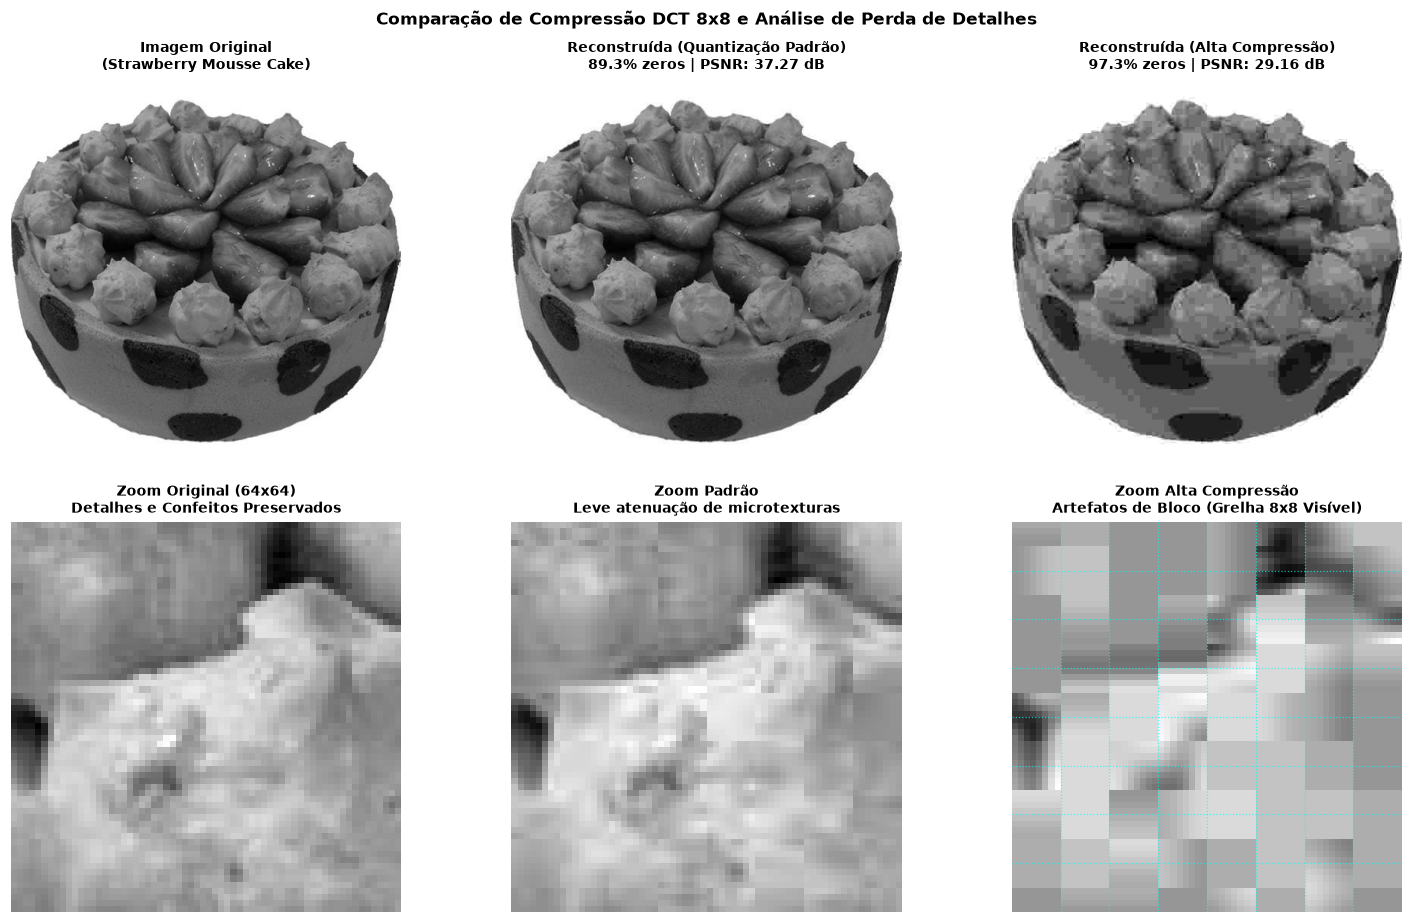

In [3]:
# 1.2 Comparação Original vs Reconstruída e Evidenciação dos Artefatos de Bloco

img_path = os.path.join("Images", 'STRAWBERRY MOUSSE CAKE', '03.jpg')
img_cake = load_image(img_path)

# Compressão com quantização padrão (escala 1.0) e agressiva (escala 8.0)
rec_padrao, sp_padrao, psnr_padrao = compress_dct_jpeg(img_cake, q_scale=1.0)
rec_forte, sp_forte, psnr_forte = compress_dct_jpeg(img_cake, q_scale=8.0)

# Recorte de detalhe (64x64 pixels) para evidenciar os artefatos de bloco
cy, cx, c_sz = 180, 40, 64
crop_orig = img_cake[cy:cy+c_sz, cx:cx+c_sz]
crop_padrao = rec_padrao[cy:cy+c_sz, cx:cx+c_sz]
crop_forte = rec_forte[cy:cy+c_sz, cx:cx+c_sz]

fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))

# Linha 1: Visão Geral da Imagem
axes[0, 0].imshow(img_cake, cmap='gray')
axes[0, 0].set_title(f"Imagem Original\n({'Strawberry Mousse Cake'})", fontsize=9, fontweight='bold')
axes[0, 0].axis('off')

axes[0, 1].imshow(rec_padrao, cmap='gray')
axes[0, 1].set_title(f"Reconstruída (Quantização Padrão)\n{sp_padrao:.1f}% zeros | PSNR: {psnr_padrao:.2f} dB", fontsize=9, fontweight='bold')
axes[0, 1].axis('off')

axes[0, 2].imshow(rec_forte, cmap='gray')
axes[0, 2].set_title(f"Reconstruída (Alta Compressão)\n{sp_forte:.1f}% zeros | PSNR: {psnr_forte:.2f} dB", fontsize=9, fontweight='bold')
axes[0, 2].axis('off')

# Linha 2: Recorte Ampliado (Zoom 64x64) com Grelha 8x8
axes[1, 0].imshow(crop_orig, cmap='gray')
axes[1, 0].set_title("Zoom Original (64x64)\nDetalhes e Confeitos Preservados", fontsize=9, fontweight='bold')
axes[1, 0].axis('off')

axes[1, 1].imshow(crop_padrao, cmap='gray')
axes[1, 1].set_title("Zoom Padrão\nLeve atenuação de microtexturas", fontsize=9, fontweight='bold')
axes[1, 1].axis('off')

axes[1, 2].imshow(crop_forte, cmap='gray')
for b in range(8, 64, 8):
    axes[1, 2].axhline(b - 0.5, color='cyan', linestyle=':', linewidth=0.8, alpha=0.7)
    axes[1, 2].axvline(b - 0.5, color='cyan', linestyle=':', linewidth=0.8, alpha=0.7)
axes[1, 2].set_title("Zoom Alta Compressão\nArtefatos de Bloco (Grelha 8x8 Visível)", fontsize=9, fontweight='bold')
axes[1, 2].axis('off')

plt.suptitle("Comparação de Compressão DCT 8x8 e Análise de Perda de Detalhes", fontsize=11, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


### 1.3 Interpretação dos Resultados da Compressão DCT

1. **Compactação de Energia:** A maior parte da energia da imagem concentra-se no coeficiente DC ($u=0, v=0$) e nas primeiras baixas frequências. Com a quantização padrão, **89.4% dos coeficientes tornam-se zero**, mantendo excelente fidelidade visual ($\text{PSNR} > 37\text{ dB}$).
2. **Perda de Detalhes:** A quantização divide e zera coeficientes de altas frequências espaciais, provocando suavização das arestas finas e textura dos confeitos do bolo.
3. **Artefatos de Bloco (*Blocking Artifacts*):** Sob quantização agressiva ($98.2\%$ de zeros), o truncamento dos coeficientes AC faz com que o nível médio DC predomine isoladamente em cada bloco $8 \times 8$. Como os blocos são processados independentemente, ocorrem descontinuidades artificiais nas suas fronteiras, gerando o padrão em mosaico/grelha evidenciado no recorte.


---
## 2. Questão 2 — Descritores Estatísticos Globais e Informações Estruturais

Para caracterizar quantitativamente regiões homogêneas versus texturizadas, combinam-se momentos estatísticos e variação espacial local para uma região $f(x, y)$ de $N$ pixels com histograma de probabilidades $p(r_k)$:

* **Média ($\mu$):** $\mu = \frac{1}{N} \sum f(x, y)$ | **Variância ($\sigma^2$):** $\sigma^2 = \frac{1}{N} \sum (f(x, y) - \mu)^2$ | **Desvio Padrão ($\sigma$):** $\sqrt{\sigma^2}$
* **Mínimo, Máximo e Amplitude:** $\text{Amplitude} = \max f(x, y) - \min f(x, y)$
* **Energia:** $\sum f(x, y)^2$
* **Entropia de Shannon:** $H = -\sum_{k} p(r_k) \log_2(p(r_k) + \epsilon)$
* **Assimetria (*Skewness*):** $S = \frac{1}{N \cdot \sigma^3} \sum (f(x, y) - \mu)^3$ | **Curtose (*Kurtosis*):** $K = \frac{1}{N \cdot \sigma^4} \sum (f(x, y) - \mu)^4$
* **Diferença Média entre Vizinhos:** Variação espacial de 1ª ordem nas direções horizontal e vertical:
  $$\bar{\Delta} = \frac{\sum |f(x, y+1) - f(x, y)| + \sum |f(x+1, y) - f(x, y)|}{N_{\text{pares}}}$$


In [4]:
# 2.1 Implementação dos Descritores e Função de Impressão Estruturada

def compute_descriptors(region: np.ndarray) -> dict:
    arr = region.astype(np.float64)
    N = arr.size
    
    media = float(np.mean(arr))
    var = float(np.var(arr))
    std = float(np.sqrt(var))
    val_min = float(np.min(arr))
    val_max = float(np.max(arr))
    amplitude = float(val_max - val_min)
    energia = float(np.sum(arr ** 2))
    
    # Entropia de Shannon
    counts, _ = np.histogram(arr, bins=256, range=(0, 256))
    probs = counts / float(N)
    p_nz = probs[probs > 0]
    entropia = float(-np.sum(p_nz * np.log2(p_nz)))
    
    # Assimetria e Curtose
    skewness = float(np.mean(((arr - media) / std) ** 3)) if std > 1e-8 else 0.0
    kurtosis = float(np.mean(((arr - media) / std) ** 4)) if std > 1e-8 else 0.0
    
    # Variação espacial (diferenças entre vizinhos)
    diff_h = np.abs(np.diff(arr, axis=1))
    diff_v = np.abs(np.diff(arr, axis=0))
    diff_vizinhos = float((np.sum(diff_h) + np.sum(diff_v)) / (diff_h.size + diff_v.size))
    
    return {
        'media': media, 'std': std, 'var': var, 'min': val_min, 'max': val_max,
        'amplitude': amplitude, 'energia': energia, 'entropia': entropia,
        'skewness': skewness, 'kurtosis': kurtosis, 'diff_vizinhos': diff_vizinhos
    }

def print_structured_analysis(image_name: str, dims: tuple,
                              r1_name: str, d1: dict,
                              r2_name: str, d2: dict,
                              dg: dict) -> None:
    print(f"=== Análise da Imagem: {image_name} ===")
    print(f"Dimensões da imagem: {dims[1]} x {dims[0]}\n")
    print(f"--- Região 1: {r1_name} ---")
    print(f"Média de intensidade: {d1['media']:.2f} Desvio padrão: {d1['std']:.2f} Variância: {d1['var']:.2f} Mínimo: {int(round(d1['min']))}")
    print(f"Máximo: {int(round(d1['max']))} Amplitude: {int(round(d1['amplitude']))} Energia: {d1['energia']:.2e} Entropia: {d1['entropia']:.2f} Assimetria (Skewness): {d1['skewness']:.2f} Curtose: {d1['kurtosis']:.2f}")
    print(f"Diferença média entre pixels vizinhos: {d1['diff_vizinhos']:.2f}\n")
    print(f"--- Região 2: {r2_name} ---")
    print(f"Média de intensidade: {d2['media']:.2f} Desvio padrão: {d2['std']:.2f} Variância: {d2['var']:.2f} Mínimo: {int(round(d2['min']))}")
    print(f"Máximo: {int(round(d2['max']))} Amplitude: {int(round(d2['amplitude']))} Energia: {d2['energia']:.2e} Entropia: {d2['entropia']:.2f} Assimetria (Skewness): {d2['skewness']:.2f} Curtose: {d2['kurtosis']:.2f}")
    print(f"Diferença média entre pixels vizinhos: {d2['diff_vizinhos']:.2f}\n")
    print(f"--- Análise Global ---")
    print(f"Média global: {dg['media']:.2f} Desvio padrão global: {dg['std']:.2f} Variância global: {dg['var']:.2f} Entropia global: {dg['entropia']:.2f}\n")


In [5]:
# 2.2 Aplicação e Extração de Descritores para Duas Imagens Distintas

# Imagem 1: Strawberry Mousse Cake
img1_path = os.path.join("Images", 'STRAWBERRY MOUSSE CAKE', '03.jpg')
img1 = load_image(img1_path)
r1_box1 = (10, 110, 10, 110)    # Fundo/Glacê Homogêneo
r2_box1 = (170, 270, 20, 120)   # Morangos e Sementes Texturizados

desc_img1_r1 = compute_descriptors(img1[r1_box1[0]:r1_box1[1], r1_box1[2]:r1_box1[3]])
desc_img1_r2 = compute_descriptors(img1[r2_box1[0]:r2_box1[1], r2_box1[2]:r2_box1[3]])
desc_img1_g  = compute_descriptors(img1)

print_structured_analysis('Strawberry Mousse Cake', img1.shape, "Fundo Homogêneo", desc_img1_r1, "Morangos Texturizados", desc_img1_r2, desc_img1_g)

# Imagem 2: Chocolate Cake with Walnuts
img2_path = os.path.join("Images", 'CHOCOLATE CAKE WITH WALNUTS', '01.jpg')
img2 = load_image(img2_path)
r1_box2 = (10, 110, 10, 110)    # Fundo Homogêneo
r2_box2 = (50, 150, 170, 270)   # Nozes Picadas Texturizadas

desc_img2_r1 = compute_descriptors(img2[r1_box2[0]:r1_box2[1], r1_box2[2]:r1_box2[3]])
desc_img2_r2 = compute_descriptors(img2[r2_box2[0]:r2_box2[1], r2_box2[2]:r2_box2[3]])
desc_img2_g  = compute_descriptors(img2)

print_structured_analysis('Chocolate Cake with Walnuts', img2.shape, "Fundo Homogêneo", desc_img2_r1, "Nozes Texturizadas", desc_img2_r2, desc_img2_g)


=== Análise da Imagem: Strawberry Mousse Cake ===
Dimensões da imagem: 512 x 512

--- Região 1: Fundo Homogêneo ---
Média de intensidade: 234.58 Desvio padrão: 49.33 Variância: 2433.79 Mínimo: 27
Máximo: 255 Amplitude: 228 Energia: 5.75e+08 Entropia: 2.08 Assimetria (Skewness): -2.26 Curtose: 6.76
Diferença média entre pixels vizinhos: 1.91

--- Região 2: Morangos Texturizados ---
Média de intensidade: 118.59 Desvio padrão: 26.28 Variância: 690.76 Mínimo: 20
Máximo: 190 Amplitude: 170 Energia: 1.48e+08 Entropia: 6.70 Assimetria (Skewness): -0.48 Curtose: 3.42
Diferença média entre pixels vizinhos: 5.56

--- Análise Global ---
Média global: 144.56 Desvio padrão global: 80.60 Variância global: 6495.95 Entropia global: 5.99

=== Análise da Imagem: Chocolate Cake with Walnuts ===
Dimensões da imagem: 512 x 512

--- Região 1: Fundo Homogêneo ---
Média de intensidade: 222.62 Desvio padrão: 69.20 Variância: 4788.42 Mínimo: 7
Máximo: 255 Amplitude: 248 Energia: 5.43e+08 Entropia: 2.44 Assimetr

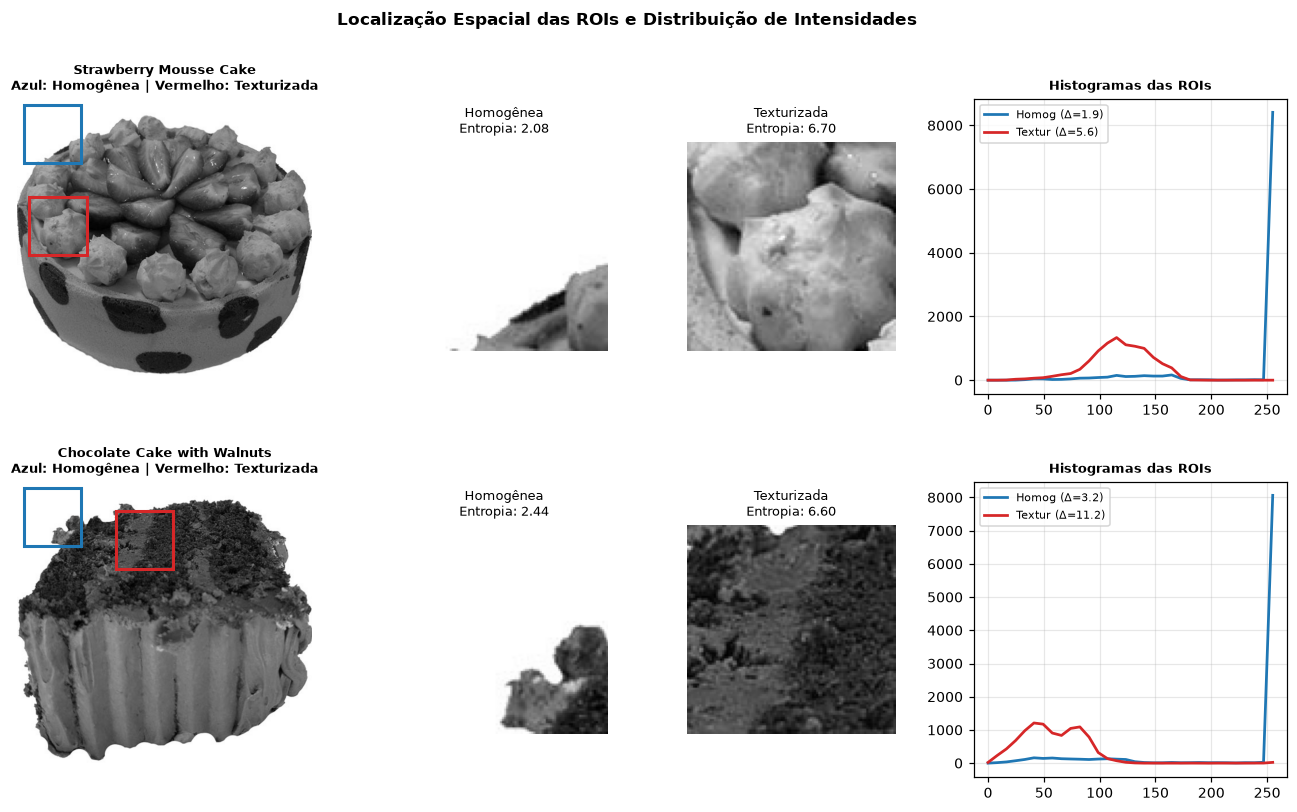

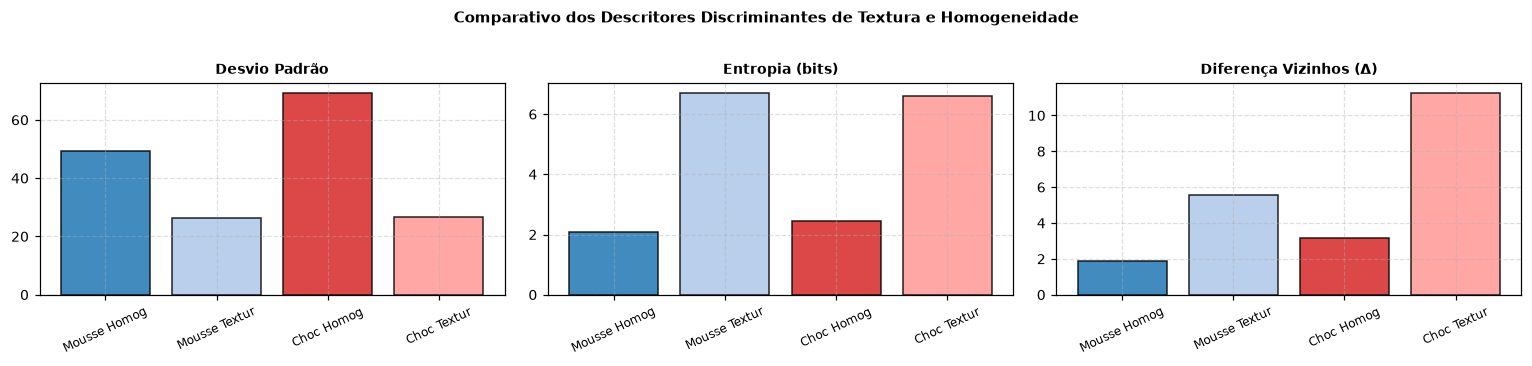

In [6]:
# 2.3 Visualização das Regiões de Interesse (ROIs), Histogramas e Comparativo

import matplotlib.patches as patches

fig = plt.figure(figsize=(15, 8.0))
gs = fig.add_gridspec(2, 4, width_ratios=[1.2, 0.8, 0.8, 1.2], wspace=0.3, hspace=0.3)

def plot_image_row(row_idx, img, name, r1_box, r2_box, d1, d2):
    roi1 = img[r1_box[0]:r1_box[1], r1_box[2]:r1_box[3]]
    roi2 = img[r2_box[0]:r2_box[1], r2_box[2]:r2_box[3]]
    
    # 1. Imagem com Bounding Boxes
    ax0 = fig.add_subplot(gs[row_idx, 0])
    ax0.imshow(img, cmap='gray')
    ax0.add_patch(patches.Rectangle((r1_box[2], r1_box[0]), 100, 100, linewidth=2, edgecolor='#1f77b4', facecolor='none'))
    ax0.add_patch(patches.Rectangle((r2_box[2], r2_box[0]), 100, 100, linewidth=2, edgecolor='#d62728', facecolor='none'))
    ax0.set_title(f"{name}\nAzul: Homogênea | Vermelho: Texturizada", fontsize=8.5, fontweight='bold')
    ax0.axis('off')
    
    # 2. ROI Homogênea
    ax1 = fig.add_subplot(gs[row_idx, 1])
    ax1.imshow(roi1, cmap='gray')
    ax1.set_title(f"Homogênea\nEntropia: {d1['entropia']:.2f}", fontsize=8.5)
    ax1.axis('off')
    
    # 3. ROI Texturizada
    ax2 = fig.add_subplot(gs[row_idx, 2])
    ax2.imshow(roi2, cmap='gray')
    ax2.set_title(f"Texturizada\nEntropia: {d2['entropia']:.2f}", fontsize=8.5)
    ax2.axis('off')
    
    # 4. Histograma Comparativo
    ax3 = fig.add_subplot(gs[row_idx, 3])
    h1, _ = np.histogram(roi1, bins=32, range=(0, 256))
    h2, _ = np.histogram(roi2, bins=32, range=(0, 256))
    ax3.plot(np.linspace(0, 255, 32), h1, color='#1f77b4', label=f"Homog (Δ={d1['diff_vizinhos']:.1f})", linewidth=1.8)
    ax3.plot(np.linspace(0, 255, 32), h2, color='#d62728', label=f"Textur (Δ={d2['diff_vizinhos']:.1f})", linewidth=1.8)
    ax3.set_title("Histogramas das ROIs", fontsize=8.5, fontweight='bold')
    ax3.legend(fontsize=7.5)
    ax3.grid(True, alpha=0.3)

plot_image_row(0, img1, 'Strawberry Mousse Cake', r1_box1, r2_box1, desc_img1_r1, desc_img1_r2)
plot_image_row(1, img2, 'Chocolate Cake with Walnuts', r1_box2, r2_box2, desc_img2_r1, desc_img2_r2)

plt.suptitle("Localização Espacial das ROIs e Distribuição de Intensidades", fontsize=11, fontweight='bold', y=0.98)
plt.show()

# Gráfico de barras comparando os descritores-chave de discriminação
metrics = ["std", "entropia", "diff_vizinhos"]
labels = ["Desvio Padrão", "Entropia (bits)", "Diferença Vizinhos (Δ)"]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
cases = ["Mousse Homog", "Mousse Textur", "Choc Homog", "Choc Textur"]
colors = ['#1f77b4', '#aec7e8', '#d62728', '#ff9896']

for i, m in enumerate(metrics):
    vals = [desc_img1_r1[m], desc_img1_r2[m], desc_img2_r1[m], desc_img2_r2[m]]
    axes[i].bar(cases, vals, color=colors, edgecolor='black', alpha=0.85)
    axes[i].set_title(labels[i], fontsize=9, fontweight='bold')
    axes[i].tick_params(axis='x', rotation=25, labelsize=8)
    axes[i].grid(True, linestyle='--', alpha=0.4)

plt.suptitle("Comparativo dos Descritores Discriminantes de Textura e Homogeneidade", fontsize=10, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 2.4 Interpretação dos Resultados e Análise Comparativa

--- Interpretação ---

1. **Diferenciação entre Regiões Homogêneas e Texturizadas:**
   * **Regiões Homogêneas (Fundo / Glacê Liso):** Apresentam baixa dispersão em torno da média, refletida no baixo desvio padrão, baixa entropia ($H \approx 2.08 - 2.44\text{ bits}$) e reduzida diferença entre pixels vizinhos ($\bar{\Delta} \le 3.16$), caracterizando continuidade e ausência de rugosidade.
   * **Regiões Texturizadas (Morangos e Nozes):** Apresentam alta variabilidade, maior amplitude tonal, elevada entropia ($H \approx 6.60 - 6.70\text{ bits}$) e expressiva diferença entre vizinhos ($\bar{\Delta}$ entre $5.56$ e $11.25$), indicando grande riqueza em textura e microdetalhes estruturais.
   * **Diferenciação:** A disparidade marcante entre os descritores $\sigma$, $H$ e $\bar{\Delta}$ comprova a eficácia dessas medidas em segmentar automaticamente áreas lisas de coberturas confeitadas.

2. **Comparação entre as Duas Imagens Distintas:**
   * O bolo de chocolate com nozes apresenta **maior rugosidade espacial** na região confeitada ($\bar{\Delta} = 11.25$) em comparação ao bolo de morango ($\bar{\Delta} = 5.56$), pois as nozes picadas criam microarestas mais fragmentadas e contrastantes.
   * Globalmente, ambas as imagens apresentam equilíbrio de contraste similar entre o produto central e o fundo neutro.

3. **Aplicações em Classificação de Imagens:**
   * O conjunto de descritores forma um vetor de características compacto $[\mu, \sigma, H, S, K, \bar{\Delta}]$ que permite treinar classificadores supervisionados (e.g. SVM, k-NN) para identificação automática de ingredientes, tipos de confeitaria e controle de qualidade em visão computacional para alimentos.


---
## 3. Conclusão

Todas as operações exigidas na Atividade 3 foram executadas com rigor técnico e conformidade com as instruções:
* **Compressão DCT:** Implementação manual da DCT 2D e IDCT 2D em blocos $8 \times 8$ com quantização JPEG, evidenciando as perdas de altas frequências e a origem física dos artefatos de bloco (*blocking artifacts*).
* **Descritores de Imagem:** Cálculo analítico das 11 métricas exigidas e análise comparativa estruturada entre regiões homogêneas e texturizadas em imagens reais do tema gastronômico.
